In [96]:
import os
import re
from datetime import datetime
import pandas as pd
import numpy as np
from plotnine import *
import baltic as bt
from geopy.distance import geodesic
# import geopandas as gpd
# import geodatasets
# from shapely.geometry import Polygon, MultiPolygon
# import json
# import sys
# import subprocess
import glob
# import shutil
import importlib
# import matplotlib as mpl

In [97]:
def load_tree(nexusPath):
    mytree = bt.loadNexus(nexusPath, tip_regex='\|([0-9]{4}\-[0-9]{2}\-[0-9]{2})', absoluteTime=True, verbose=False) # your tip regex might have to change or you could convert you tree into a newick by deleting everything before the tree string lol
    return(mytree)

In [98]:
# nexusPath="./SERAPHIM/nov2021-2024_no-suliformes/NAm_wild-aves_nov2021-2024_no-suliformes_ha_contphyl_2025-08-18_MCC.tree" # your path here
# nexusPath = "./SERAPHIM/main-intro_equal-time-host-1000/main-intro_equal-time-host-1000_ha_traits_MCC.tree"
# nexusPath = "./SERAPHIM/main-intro_equal-time-host-3000/main-intro_equal-time-host-3000_ha_traits_MCC.tree"
# nexusPath = "./SERAPHIM/main-intro_liveharvest/main-intro_liveharvest_ha_traits_MCC.tree"
# nexusPath = "./SERAPHIM/main-intro_prop-time-loc/main-intro_prop-time-loc_ha_traits_noLP_MCC.tree"
nexusPath = "./SERAPHIM/main-intro_prop-time-host/main-intro_prop-time-host_ha_traits_noLP_MCC.tree"

In [99]:
# Load tree

mytree = load_tree(nexusPath)

In [100]:
print(type(mytree))

<class 'baltic.baltic.tree'>


In [101]:
print(mytree.treeStats())


Tree height: 3.283895
Tree length: 177.553757
strictly bifurcating tree

Numbers of objects in tree: 1913 (956 nodes and 957 leaves)

None


In [102]:
print(mytree.Objects[9].absoluteTime)

2022.0794520547945


In [103]:
# Add a label for each object in mytree

label_count = 0

for k in mytree.Objects:
    k.label = label_count
    label_count += 1

In [104]:
print(mytree.Objects[3].parent)

thiscount = 0

for k in mytree.Objects:
    if thiscount < 1:
        if k.is_leaf():
            print(k.name)
            thiscount += 1

a/mallard/northcarolina/22004008006/2022|2022-02-01|wild|anseriformes|AtlanticFlyway


In [105]:
def backwards(leaf, path_to_leaf, t, time):
    if time < t:
        path_to_leaf.append(leaf.parent)
        time += leaf.traits["length"]

        if leaf.parent.absoluteTime == None: # if parent is the root
            pass
        else:
            path_to_leaf = backwards(leaf.parent, path_to_leaf,t, time)
        
    return(path_to_leaf) # to add the latest node as a new "leaf", just print latest node and start afresh

In [106]:
count = 0
parents = {}

for k in mytree.Objects:
    # t = 0.25 # 0.25 years is about 3 months
    t = 0.0833 # 0.0833 years is about 1 month
    # if count < 30:
    if k.is_node():
        pass
    else:
        path_to_leaf = []
        time = 0
        path_to_leaf = backwards(k, path_to_leaf, t, time)
        # parents = defaultdict(path_to_leaf)
        # parents[k.name] = path_to_leaf
        parents.update({k:{"path":path_to_leaf}})
        # count += 1

In [107]:
# Pick just the node furthest back in time

for key in parents:
    
    parents[key]["earliest_node"] = []

    list_of_nodes = parents[key]["path"]

    node_times_dict = {}
    for node in list_of_nodes:
        if node.absoluteTime == None: # Just in case the root is the node 3 months away from a tip
            pass
        else:
            node_times_dict.update({node:node.absoluteTime}) 

    min_key = min(node_times_dict, key=lambda k: node_times_dict[k]) # takes the minimum value in the dictionary, sets a function using lambda to return the key of that minimum
    # print("Key with minimum value:", min_key)

    parents[key]["earliest_node"] = min_key

In [108]:
# Calculate distance between leaf and each node

In [109]:
def calc_dist(node, leaf_lat, leaf_long):
    # For each node, pull the lat/long
    node_lat = node.traits["location1"]
    node_long = node.traits["location2"]

    # Establish coordinates
    start = (node_lat, node_long)
    end = (leaf_lat, leaf_long)

    # Calculate distance
    dist = geodesic(start, end, ellipsoid='GRS-80').kilometers

    return(dist)

In [110]:
# Calculate direction of movement

In [111]:
def calc_direction(node, leaf_lat, leaf_long):
    # For each node, pull the lat/long
    node_lat = node.traits["location1"]
    node_long = node.traits["location2"]

    # Calculate change in latitude (and set to direction)
    changeLat = float(leaf_lat - node_lat)
    # print(changeLat)
    if changeLat < 0:
        directLat = "south"
    elif changeLat > 0:
        directLat = "north"
    else:
        directLat = "none"

    # Calculate change in longitude (and set to direction)
    changeLong = float(leaf_long - node_long)
    # print(changeLong)
    if changeLong < 0:
        directLong = "west"
    elif changeLong > 0:
        directLong = "east"
    else:
        directLong = "none"

    # Combine
    return(changeLat, changeLong, directLat, directLong)
    # return(directLat_directLong)

In [112]:
# Calcuate the season of the starting point (i.e. the node)

In [113]:
def get_season(y):
    if y <= 2021.96986: # late autumn 2021
        return "autumn"
    elif 2021.96986 < y <= 2022.21096: # winter 2021-22
        return "winter"
    elif 2022.21096 < y <= 2022.46575: # spring 2022
        return "spring"
    elif 2022.46575 < y <= 2022.72055: # summer 2022
        return "summer"
    elif 2022.72055 < y <= 2022.96712: # autumn 2022
        return "autumn"
    elif 2022.96712 < y <= 2023.21096: # winter 2022-23
        return "winter"
    elif 2023.21096 < y <= 2023.46575: # spring 2023
        return "spring"
    elif 2023.46575 < y <= 2023.72329: # summer 2023
        return "summer"
    elif 2023.72329 < y <= 2023.96712: # autumn 2023
        return "autumn"
    elif 2023.96712 < y <= 2024.21038: # winter 2023-24
        return "winter"
    elif 2024.21038 < y <= 2024.46448: # spring 2024
        return "spring"
    elif 2024.46448 < y <= 2024.72131: # summer 2024
        return "summer"
    elif 2024.72131 < y <= 2024.96721: # autumn 2024
        return "autumn"
    elif y > 2024.96721: # winter 2024
        return "winter"
    else:
        return "unknown"

In [114]:
def calc_nodeseason(node):
    
    node_time = node.absoluteTime

    # Assign season to leaf and node
    season = get_season(node_time)
    
    return(season)

In [115]:
# Calculate the year and season together

In [116]:
def get_seasonyear(y):
    if y <= 2021.96986: # late autumn 2021
        return "autumn_2021"
    elif 2021.96986 < y <= 2022.21096: # winter 2021-22
        return "winter_2021/22"
    elif 2022.21096 < y <= 2022.46575: # spring 2022
        return "spring_2022"
    elif 2022.46575 < y <= 2022.72055: # summer 2022
        return "summer_2022"
    elif 2022.72055 < y <= 2022.96712: # autumn 2022
        return "autumn_2022"
    elif 2022.96712 < y <= 2023.21096: # winter 2022-23
        return "winter_2022/23"
    elif 2023.21096 < y <= 2023.46575: # spring 2023
        return "spring_2023"
    elif 2023.46575 < y <= 2023.72329: # summer 2023
        return "summer_2023"
    elif 2023.72329 < y <= 2023.96712: # autumn 2023
        return "autumn_2023"
    elif 2023.96712 < y <= 2024.21038: # winter 2023-24
        return "winter_2023/24"
    elif 2024.21038 < y <= 2024.46448: # spring 2024
        return "spring_2024"
    elif 2024.46448 < y <= 2024.72131: # summer 2024
        return "summer_2024"
    elif 2024.72131 < y <= 2024.96721: # autumn 2024
        return "autumn_2024"
    elif y > 2024.96721: # winter 2024
        return "winter_2024"
    else:
        return "unknown"

In [117]:
def get_monthyear(y):
    if 2021.665753 <= y < 2021.747945: 
        return "2021_september"
    elif 2021.747945 <= y < 2021.832877: 
        return "2021_october"
    elif 2021.832877 <= y < 2021.915068: 
        return "2021_november"
    elif 2021.915068 <= y < 2022.000000: 
        return "2021_december"
    elif 2022.000000 <= y < 2022.084932: 
        return "2022_january"
    elif 2022.084932 <= y < 2022.161644:
        return "2022_february"
    elif 2022.161644 <= y < 2022.246575:
        return "2022_march"
    elif 2022.246575 <= y < 2022.328767:
        return "2022_april"
    elif 2022.328767 <= y < 2022.413699:
        return "2022_may"
    elif 2022.413699 <= y < 2022.495890:
        return "2022_june"
    elif 2022.495890 <= y < 2022.580822:
        return "2022_july"
    elif 2022.580822 <= y < 2022.665753:
        return "2022_august"
    elif 2022.665753 <= y < 2022.747945:
        return "2022_september"
    elif 2022.747945 <= y < 2022.832877: 
        return "2022_october"
    elif 2022.832877 <= y < 2022.915068:
        return "2022_november"
    elif 2022.915068 <= y < 2023.000000:
        return "2022_december"
    elif 2023.000000 <= y < 2023.084932:
        return "2023_january"
    elif 2023.084932 <= y < 2023.161644:
        return "2023_february"
    elif 2023.161644 <= y < 2023.246575:
        return "2023_march"
    elif 2023.246575 <= y < 2023.328767:
        return "2023_2023_april"
    elif 2023.328767 <= y < 2023.413699:
        return "2023_may"
    elif 2023.413699 <= y < 2023.495890:
        return "2023_june"
    elif 2023.495890 <= y < 2023.580822:
        return "2023_july"
    elif 2023.580822 <= y < 2023.665753:
        return "2023_august"
    elif 2023.665753 <= y < 2023.747945:
        return "2023_september"
    elif 2023.747945 <= y < 2023.832877:
        return "2023_october"
    elif 2023.832877 <= y < 2023.915068:
        return "2023_november"
    elif 2023.915068 <= y < 2024.000000:
        return "2023_december"
    elif 2024.000000 <= y < 2024.084699:
        return "2024_january"
    elif 2024.084699 <= y < 2024.163934:
        return "2024_february"
    elif 2024.163934 <= y < 2024.248634:
        return "2024_march"
    elif 2024.248634 <= y < 2024.330601:
        return "2024_april"
    elif 2024.330601 <= y < 2024.415301:
        return "2024_may"
    elif 2024.415301 <= y < 2024.497268:
        return "2024_june"
    elif 2024.497268 <= y < 2024.581967:
        return "2024_july"
    elif 2024.581967 <= y < 2024.666667:
        return "2024_august"
    elif 2024.666667 <= y < 2024.748634:
        return "2024_september"
    elif 2024.748634 <= y < 2024.833333:
        return "2024_october"
    elif 2024.833333 <= y < 2024.915301:
        return "2024_november"
    elif y >= 2024.915301:
        return "2024_december"
    else:
        return "unknown"

In [118]:
def calc_timing(node):

    node_time = node.absoluteTime

    # node_year = node_time.as_type(str).str.split(".", expand = True)[0]

    node_timing = get_seasonyear(node_time)
    # node_timing = get_monthyear(node_time)

    return(node_timing)

In [119]:
# This loop calculates year, change in season, distance, change in Latitude, and change in Longitude 
def make_metadata(dictionary):
    for key in dictionary:
        
        # Set leaf (ending) latitude and longitude
        leaf_lat = key.traits["location1"]
        leaf_long = key.traits["location2"]
    
        # Use the following if you want to calculate distance, change in Latitude, and change in Longitude for each node in the path backwards
        
        # # Update the parents dictionary
        # dictionary[key]["distance"] = []
        # dictionary[key]["changeLatitude"] = []
        # dictionary[key]["changeLongitude"] = []
        # dictionary[key]["node_season"] = []
        # dictionary[key]["node_timing"] = []
    
        # # Initialize the lists 
        # distance = []
        # changeLat = []
        # changeLong = []
        # season = []
        # timing = []
    
        # nodes_backward = dictionary[key]["path"] 
        # # print(nodes_backward)
    
        # for node in nodes_backward:
        #     node_dist = calc_dist(node, leaf_lat, leaf_long)
        #     distance.append(node_dist)
        #     node_changeLat, node_changeLong = calc_direction(node, leaf_lat, leaf_long)
        #     changeLat.append(node_changeLat)
        #     changeLong.append(node_changeLong)
        #     node_season = calc_nodeseason(node)
        #     node_timing = calc_timing(node)
        #     season.append(node_season)
        #     timing.append(node_timing)
        
    
        # # print(distance)
    
        # dictionary[key]["distance"] = distance
        # dictionary[key]["changeLatitude"] = changeLat
        # dictionary[key]["changeLongitude"] = changeLong
        # dictionary[key]["node_season"] = season
        # dictionary[key]["node_timing"] = timing
    
    
        # Use this code if you want to calculate distance, change in Latitude, and change in Longitude for just the earliest node (most backwards)
        node = dictionary[key]["earliest_node"] 
        
        node_dist = calc_dist(node, leaf_lat, leaf_long)
        node_changeLat, node_changeLong, node_directLat, node_directLong = calc_direction(node, leaf_lat, leaf_long)
        node_season = calc_nodeseason(node)
        node_timing = calc_timing(node)
        node_year = str(node.absoluteTime).split(".")[0]
        node_host = node.traits["host"] #ncbibvbrc_hostgroup
        leaf_host = key.traits["host"] #ncbibvbrc_hostgroup
    
        dictionary[key]["distance"] = node_dist
        dictionary[key]["changeLatitude"] = node_changeLat
        dictionary[key]["changeLongitude"] = node_changeLong
        dictionary[key]["node_season"] = node_season
        dictionary[key]["node_timing"] = node_timing
        dictionary[key]["directionLatitude"] = node_directLat
        dictionary[key]["directionLongitude"] = node_directLong
        dictionary[key]["node_year"] = node_year
        dictionary[key]["node_host"] = node_host
        dictionary[key]["leaf_host"] = leaf_host

    return(dictionary)

In [120]:
parents = make_metadata(parents)

In [121]:
print(len(parents))

957


In [122]:
parents_df = pd.DataFrame.from_dict(parents, orient = "index")

parents_df["season_year"] = parents_df["node_season"] + "_" + parents_df["node_year"]

In [123]:
# season_year_order = ["2021_autumn", "2021_winter", "2022_spring", "2022_summer", 
#                     "2022_autumn", "2022_winter", "2023_spring", "2023_summer",
#                     "2023_autumn", "2023_winter", "2024_spring", "2024_summer",
#                     "2024_autumn"
#                     ]

month_year_order = ["2021_october","2021_november","2021_december", 
                    "2022_january", "2022_february", "2022_march", "2022_april", "2022_may", "2022_june", 
                    "2022_july", "2022_august", "2022_september", "2022_october", "2022_november", "2022_december",
                    "2023_january", "2023_february", "2023_march", "2023_april", "2023_may", "2023_june", 
                    "2023_july", "2023_august", "2023_september", "2023_october", "2023_november", "2023_december", 
                    "2024_january", "2024_february", "2024_march", "2024_april", "2024_may", "2024_june",
                    "2024_july", "2024_august", "2024_september", "2024_october", "2024_november", "2024_december"
                   ]

season_year_order = ["autumn_2021", "winter_2021/22", "spring_2022", "summer_2022", "autumn_2022","winter_2022/23", "spring_2023", "summer_2023", 
                     "autumn_2023", "winter_2023/24", "spring_2024", "summer_2024", "autumn_2024"]

parents_df["node_timing"] = pd.Categorical(parents_df["node_timing"], categories=season_year_order, ordered=True)
# parents_df["season_year"] = pd.Categorical(parents_df["season_year"], categories=season_year_order, ordered=True)
# parents_df["node_season"] = pd.Categorical(parents_df["node_season"], categories=season_order, ordered=True)
# parents_df["node_year"] = pd.Categorical(parents_df["node_year"], categories=year_order, ordered=True)

In [124]:
# Jordan suggested just doing this plot for the branches were the hosts were the same (a.k.a. non-transition branches)
# Louise agrees, and her reasoning is that the trajectory of branches that transition from one host to another is some combination of the 
# trajectory of each host, which is inherently really hard to understand and explain

parents_df_nontrans = parents_df.loc[parents_df["node_host"] == parents_df["leaf_host"]]

In [58]:
# I just want to have some of these seasons 

keep_for_presentation = ["autumn_2021","winter_2021/22","spring_2022","summer_2022","autumn_2022","winter_2022/23","spring_2023","summer_2023","autumn_2023"]

parents_presentversion = parents_df_nontrans[parents_df_nontrans["node_timing"].isin(keep_for_presentation)]

In [125]:
# grouped = parents_df.groupby("node_timing")
# grouped = parents_df.groupby("season_year")
# ["node_season", "node_year"]
grouped = parents_df_nontrans.groupby("node_timing")
# grouped = parents_presentversion.groupby("node_timing")

dictionary = {}

for group in grouped:
    dictionary[group[0]] = {}
    total = len(group[1])
    if total != 0:
        nw = len(group[1].loc[(group[1]["directionLatitude"] == "north") & (group[1]["directionLongitude"] == "west")])
        ne = len(group[1].loc[(group[1]["directionLatitude"] == "north") & (group[1]["directionLongitude"] == "east")])
        sw = len(group[1].loc[(group[1]["directionLatitude"] == "south") & (group[1]["directionLongitude"] == "west")])
        se = len(group[1].loc[(group[1]["directionLatitude"] == "south") & (group[1]["directionLongitude"] == "east")])
        # n = len(group[1].loc[group[1]["directionLatitude"] == "north"])
        # s = len(group[1].loc[group[1]["directionLatitude"] == "south"])
        prop_nw = round(((nw/total) * 100), 2)
        prop_ne = round(((ne/total) * 100), 2)
        prop_sw = round(((sw/total) * 100), 2)
        prop_se = round(((se/total) * 100), 2)
        # prop_n = round(((n/total) * 100), 2)
        # prop_s = round(((s/total) * 100), 2)
    else:
        pass
    # dictionary[group[0]] = {"percent-N": prop_n, "percent-S": prop_s}
    dictionary[group[0]] = {"percent-NW": prop_nw, "percent-NE": prop_ne, "percent-SW": prop_sw, "percent-SE": prop_se}

df = pd.DataFrame(dictionary).T

print(df)

                percent-NW  percent-NE  percent-SW  percent-SE
autumn_2021          26.09       17.39       30.43       26.09
winter_2021/22       36.89       22.33       24.27       16.50
spring_2022          26.39       20.83       30.56       22.22
summer_2022          31.05       17.37       15.26       36.32
autumn_2022          21.69       18.07       19.28       40.96
winter_2022/23       12.50       43.75        6.25       37.50
spring_2023          75.00        0.00       25.00        0.00
summer_2023          22.03       22.03       25.42       30.51
autumn_2023          20.00       15.00       35.00       30.00
winter_2023/24        8.70       21.74       26.09       43.48
spring_2024           0.00      100.00        0.00        0.00
summer_2024          66.67        0.00       33.33        0.00
autumn_2024          40.00       60.00        0.00        0.00


In [126]:
# df = df.reset_index().rename({"index":"node_timing"}, axis = 1)
df = df.reset_index().rename({"index":"node_timing"}, axis = 1)
# df["node_timing"] = pd.Categorical(df["node_timing"], categories=month_year_order, ordered=True)
df["node_timing"] = pd.Categorical(df["node_timing"], categories=season_year_order, ordered=True)


In [127]:
season_colors = {"winter":"#AA7722",
               "spring":"#5E9B82",
               "summer":"#C593D1",
               "autumn":"#2B57B3"
              }
host_colors = {"bird-of-prey":"#C43110", # red-maroon
                     "duck":"#679C48", # green 
                     "goose-swan": "#DBB730", # yellow
                     "shorebird":"#68A0A6", # blue
                     "songbird-etc":"#D9A7B0", # pink
                     "ground-bird":"#E08907", # orange
                     "diving-bird":"#503A63", # deep purple
                     "other":"#A0A0A3" # grey
                    }
season_labels = {"autumn_2021": "Autumn 2021", "winter_2021/22": "Winter 2021-22", "spring_2022": "Spring 2022", "summer_2022": "Summer 2022", 
                 "autumn_2022": "Autumn 2022","winter_2022/23": "Winter 2022-23", "spring_2023": "Spring 2023", "summer_2023": "Summer 2023", 
                 "autumn_2023": "Autumn 2023", "winter_2023/24": "Winter 2023-24", "spring_2024": "Spring 2024", "summer_2024": "Summer 2024", 
                 "autumn_2024": "Autumn 2024"}

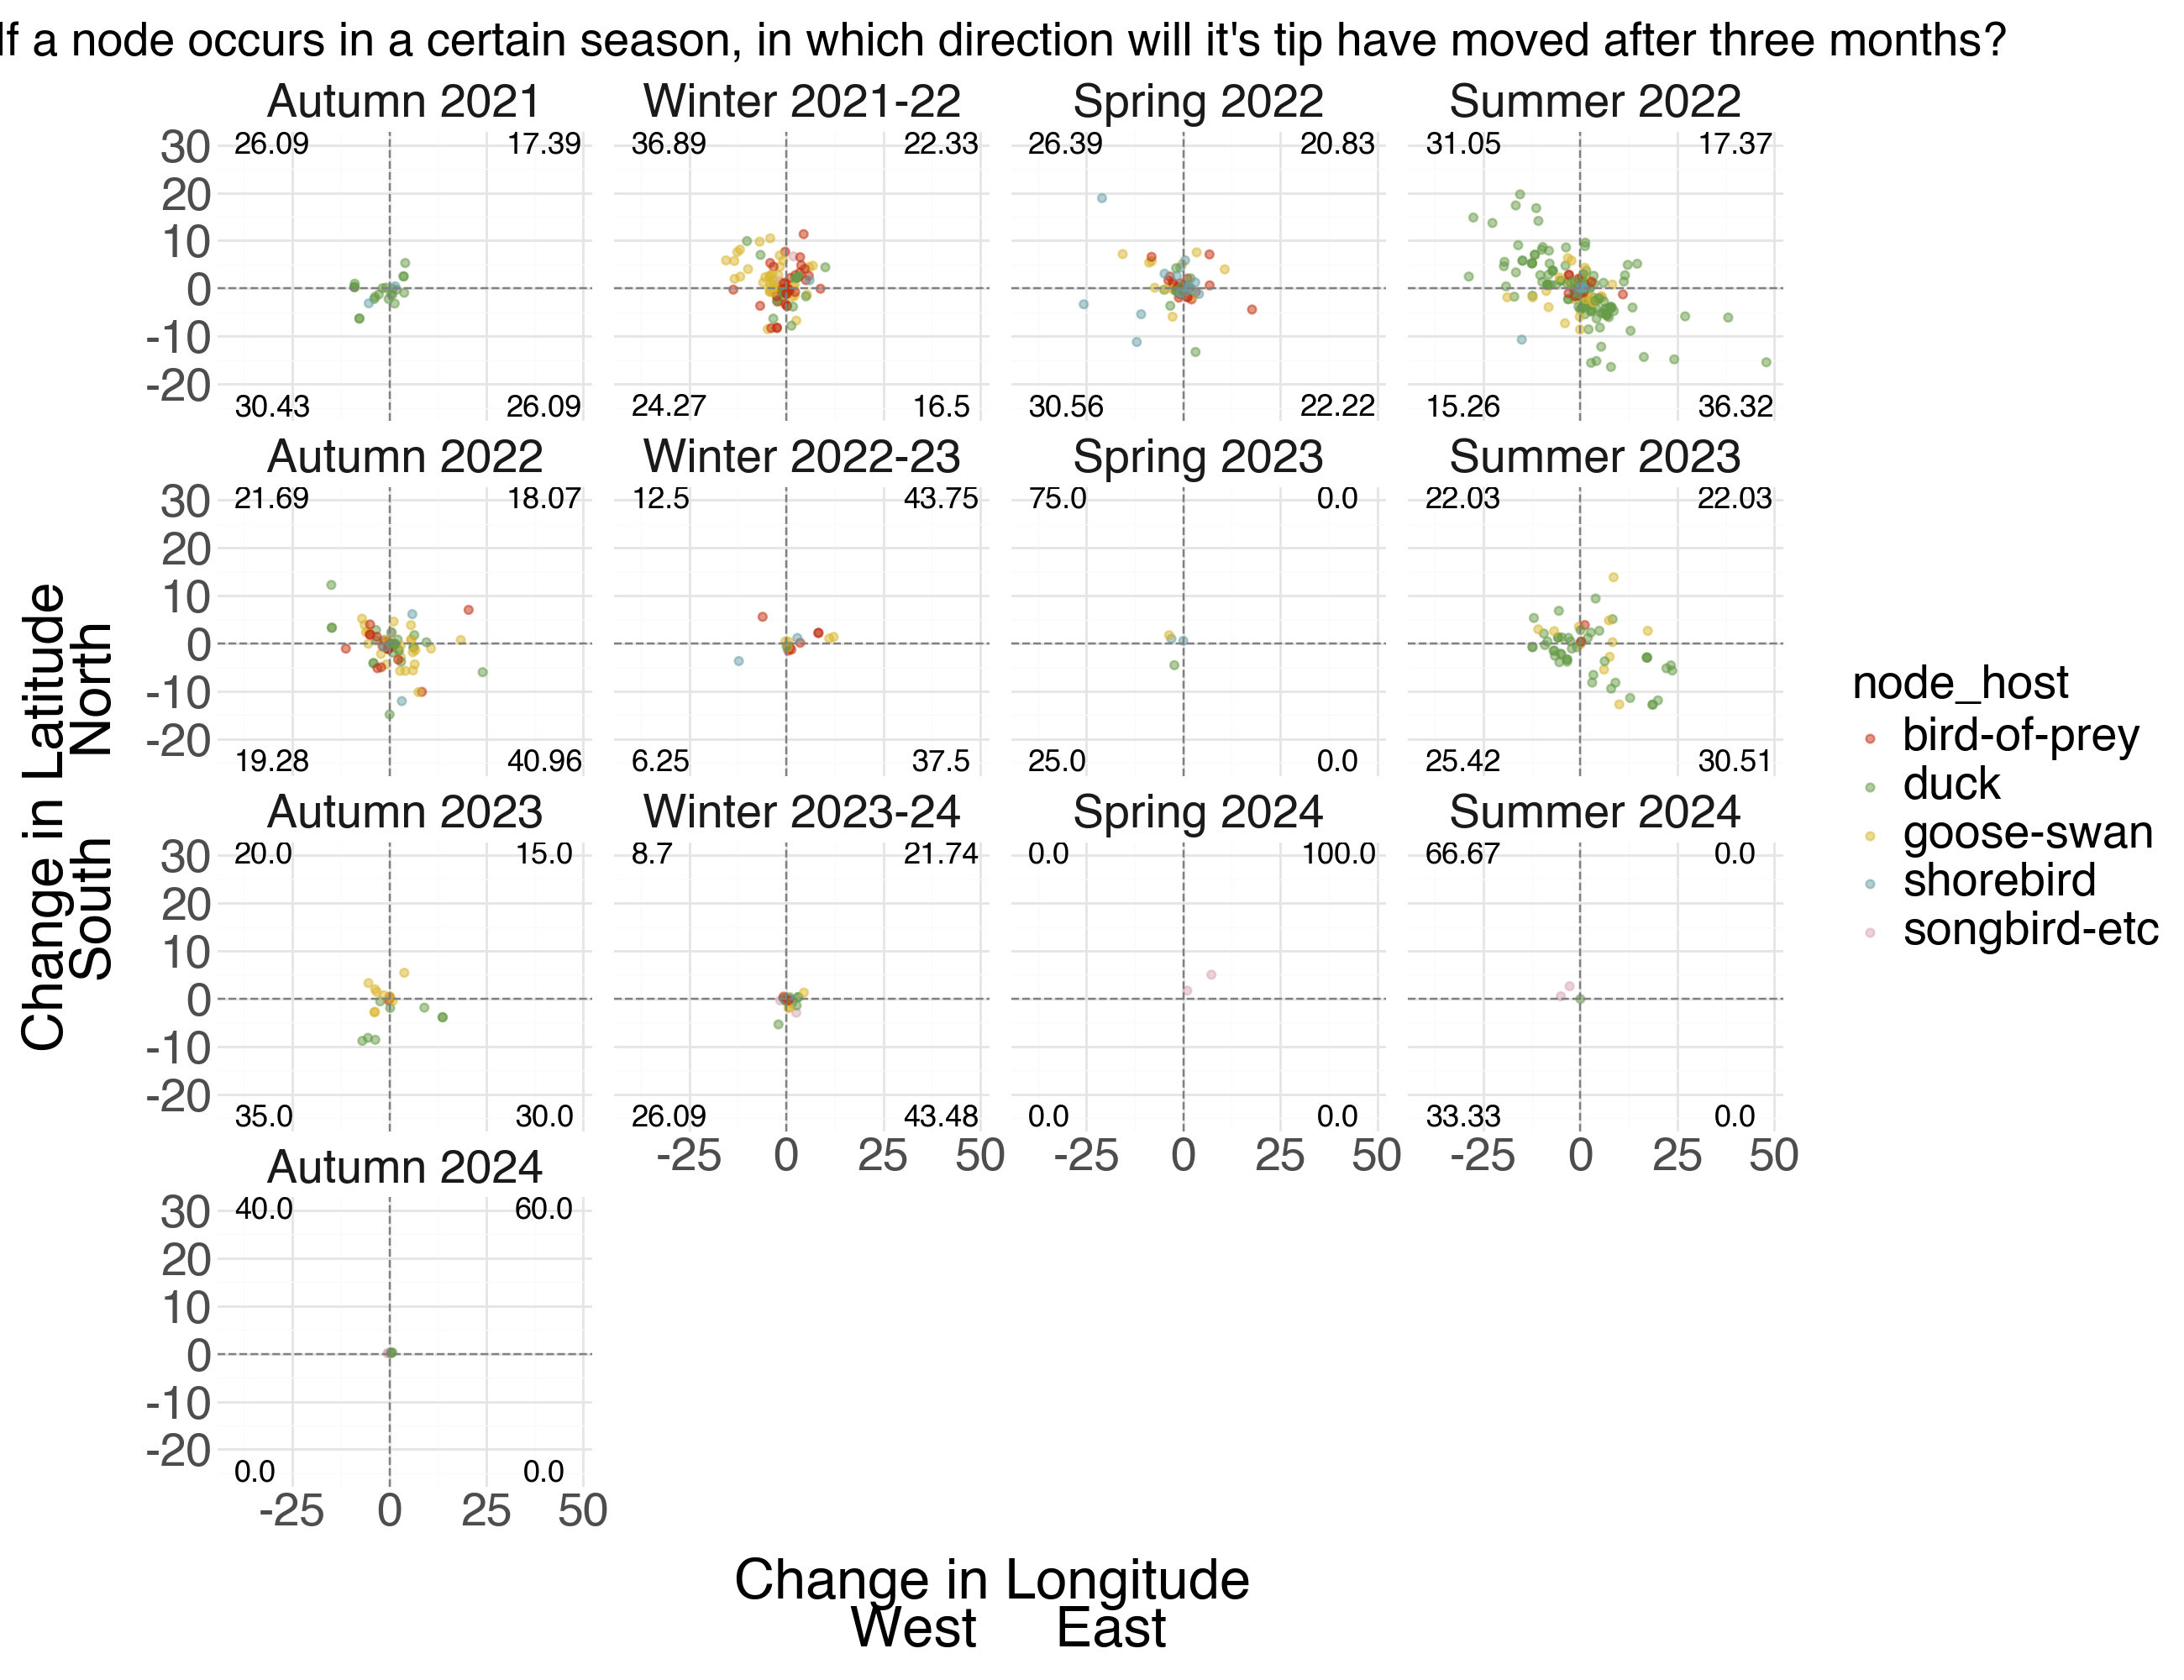

In [128]:
# Plot

trajectory = (
    ggplot(parents_df_nontrans, aes(x = "changeLongitude", y = "changeLatitude", color = "node_host"))
    + geom_point(alpha = 0.5)
    + facet_wrap("node_timing", labeller = season_labels)
    # + xlim(-15, 15)
    # + ylim(-15, 15)
    + scale_color_manual(host_colors)
    + geom_vline(xintercept = 0, linetype = "dashed", color = "grey")
    + geom_hline(yintercept = 0, linetype = "dashed", color = "grey")
    + geom_text(df, aes(x=-40, y=30, label="percent-NW"), color="black",size=13, ha='left')
    + geom_text(df, aes(x=-40, y=-25, label="percent-SW"), color="black",size=13, ha='left')
    + geom_text(df, aes(x=40, y=30, label="percent-NE"), color="black",size=13, ha='center')
    + geom_text(df, aes(x=40, y=-25, label="percent-SE"), color="black",size=13, ha='center')
    + labs(x = "Change in Longitude \n West \t\t\t East", y = "Change in Latitude \n South \t\t\t North", 
           title = "If a node occurs in a certain season, in which direction will it's tip have moved after three months?")
    + theme_minimal()
    + theme(figure_size = (13, 10), legend_text=element_text(size=20), axis_title_x = element_text(size = 24), 
            axis_title_y = element_text(size = 24), text=element_text(size=20))
)

trajectory.show()

In [129]:
# I want to save the tests in here
# trajectory.save(filename = "./SERAPHIM/main-intro_equal-time-host-3000/plots/trajectory_3months_tipcolor.pdf", height = 10, width = 15, units = "in", dpi = 750)

In [130]:
# SAVEFILE = './SERAPHIM/nov2021-2024_no-suliformes/output_plots/trajectory_3mon_percent4_2.pdf'
# SAVEFILE = "./SERAPHIM/main-intro_equal-time-host-1000/plots/trajectory_3months.pdf"
# SAVEFILE = "./SERAPHIM/main-intro_equal-time-host-3000/plots/trajectory_3months.pdf"
# SAVEFILE = "./SERAPHIM/main-intro_liveharvest/plots/trajectory_3months.pdf"
# SAVEFILE = "./SERAPHIM/main-intro_prop-time-loc/plots/trajectory_3months.pdf"
SAVEFILE = "./SERAPHIM/main-intro_prop-time-host/plots/trajectory_3months.pdf"

In [131]:
trajectory.save(filename = SAVEFILE, height=10, width=15, units = 'in', dpi=750)

/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 10 in image.
/Users/claramal/miniconda3/envs/analysis_env/lib/python3.11/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ./SERAPHIM/main-intro_prop-time-host/plots/trajectory_3months.pdf


In [7]:
# def return_all_leaves(node):
#     leaves[node.label] = node.leaves
#     # no_leaves[node.label] = len(node.leaves)
#     return leaves

In [13]:
# This loop uses the return_all_leaves function to return a dictionary of all leaves per node

parse_count = 0

for k in mytree.Objects:
    if parse_count < 10:
        if k.is_node():
            node = k
            leaves = {}
            # no_leaves = {}
            return_all_leaves(node)
            parse_count += 1
            #print(leaves)

In [87]:
# Function is meant to make a list of all the nodes in the path to each leaf

def return_path_to_leaf(node, leaf, path_to_leaf):
    for child in node.children:
        # print(f"Child: {child}, has leaves: {hasattr(child, 'leaves')}")
        # print(node.children)
        if child == leaf: # If the child is the leaf, stop parsing
            break
        elif hasattr(child, 'leaves') and leaf in child.leaves:  # Optional optimization: only go down relevant branches
            # path_to_leaf.append(child)
            path_to_leaf.append(child.label)
            return_path_to_leaf(child, leaf, path_to_leaf)
        else:
            pass

In [ ]:
parse_count = 0

for k in mytree.Objects:
    if parse_count < 2:
        if k.is_node(): # Parse through each node in the tree
            node = k
            leaves_for_node = []
            leaves_for_node.extend(node.leaves)
            parse_count += 1
            for leaf in leaves_for_node: # print a path to each leaf for each node
                path_to_leaf = []
                return_path_to_leaf(node, leaf, path_to_leaf)
            # print(leaves_for_node[0:3])
            print(path_to_leaf)

In [32]:
# for each node, go 6 months into the future and count how many node and tips have branched from that node

# t = 0.5
# count = 0
# children_count = 0
# child_dict = {}

# for k in mytree.Objects:
#     if count < 10: # only print 10 times
#         key = k.label
#         if k.is_node(): # if an object is a node, then...
#             time = k.length # time is the length of each branch
#             while time < t: # while the time is less than six months
#                 count +=1 # Increase count by one so it knows when to stop counting 
#                 if k.children[0].is_node(): # if the first of K's two children is a node...
#                     children_count += len(k.children) # count the number of childen
#                     if key not in child_dict: # If k is not already in child_dict, add it
#                         child_dict[key] = []
#                     child_dict[key].append(children_count) # Make a dictionary for the number of children in each k
#                     k = k.children[0] # Then name the node child the new k
#                     time += k.length # add the branch length of k to the time (until you get to 6 month)
#                 elif k.children[0].is_leaf(): # If the first child is a 
#                     children_count += len(k.children) # count the number of childen
#                     child_dict = child_dict[key].append(children_count) # Make a dictionary for each
#                 else:
#                     print(f"something unexpected at k {k.label}")

In [ ]:
# Original version of this code (don't want to mess with the original as I try to fix it)

# for k in mytree.Objects:
#     if count >= 10: # only do this 10 times
#         break

#     key = k.label # key is the label (number) of the node
#     time = k.length # time is the length of each branch

#     if k.is_node(): # if k is a leaf:
        
#         # node = k  # use a separate variable to traverse
    
#         while time < t: # while the time is less than six months

#             children_count = len(k.children) # count the number of childen
            
#              # Initialize list if key doesn't exist
#             if key not in child_dict:
#                 child_dict[key] = []
#             child_dict[key].append(children_count) # Make a dictionary for the number of children in each k

            
#             if k.children[0].is_node(): # if the first of K's two children is a node...

#                 children_count += 2
#                 k = k.children[0] # Then name the node child the next node
#                 time += k.length # add the branch length of k to the time (until you get to 6 month)
#                 count += 1 # Increase count by one so it knows when to stop counting
    
#             elif k.children[0].is_leaf(): # If the first child is a leaf

#                 children_count += 1
#                 count += 1 # Increase count by one so it knows when to stop counting
#                 break  # reached leaf, no further traversal
    
#             else:
#                 print(f"something unexpected at node {node.label}")
#                 # break
        
#     elif not k.is_node():
#         child_dict[key].append("not node")

In [26]:
# Second for loop, updated from my attempt by Chat GPT

t = 0.5
count = 0
child_dict = {}

for k in mytree.Objects:
    if count >= 20: # only do this 10 times
        break

    key = k.label # key is the label (number) of the node
    time = k.length # time is the length of each branch

    if k.is_node(): # if k is a leaf:
        
        # node = k  # use a separate variable to traverse
        children_count = 0
    
        while time < t: # while the time is less than six months

            # children_count = len(k.children) # count the number of childen
            
            if k.children[0].is_node(): # if the first of K's two children is a node...

                children_count += 2 # Because a node has two more children...?
                k = k.children[0] # Then name the node child the next node
                time += k.length # add the branch length of k to the time (until you get to 6 month)
                count += 1 # Increase count by one so it knows when to stop counting
    
            elif k.children[0].is_leaf(): # If the first child is a leaf

                children_count += 1 # Because a leaf is one child
                count += 1 # Increase count by one so it knows when to stop counting
                break  # reached leaf, no further traversal
    
            else:
                print(f"something unexpected at node {node.label}")
                # break
        
        # Initialize list if key doesn't exist
        if key not in child_dict:
            child_dict[key] = []
        child_dict[key].append(children_count) # Make a dictionary for the number of children in each k

    elif not k.is_node():
        child_dict[key].append("not node")